# Learning Boltzmann Distributions with Stochastic Interpolants



## Setup

$$V(x_0,x_1)=\varepsilon\left[c(x_0^2-1)^2+(x_0-x_1)^2+d(x_0+x_1)\right],$$
$$X_t = X_0\cos{\frac{\pi t}{2}}+X_1\sin{\frac{\pi t}{2}}$$


In [1]:

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

device = torch.device("mps" if torch.backends.mps.is_available() else
                      "cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: mps


In [2]:

eps = 3.0
c = 1.0
d = 0.5

def potential(x):
    x0, x1 = x
    return eps * (c * (x0**2 - 1)**2 + (x0 - x1)**2 + d * (x0 + x1))


In [3]:

def metropolis(n_samples, kBT=1.0, step_size=0.5, burn_in=5000):
    x = np.array([0.0, 0.0])
    samples = []
    accepted = 0

    total_steps = n_samples + burn_in

    for i in range(total_steps):
        proposal = x + np.random.normal(0, step_size, size=2)

        delta_V = potential(proposal) - potential(x)

        if delta_V <= 0 or np.random.rand() < np.exp(-delta_V / kBT):
            x = proposal
            accepted += 1

        if i >= burn_in:
            samples.append(x.copy())

    acceptance_rate = accepted / total_steps

    return np.array(samples), acceptance_rate


In [4]:

step_sizes = [0.1, 0.3, 0.5, 1.0, 2.0]

for step in step_sizes:
    samples, rate = metropolis(
        n_samples=10000,
        kBT=1.0,
        step_size=step
    )

    print(f"Step size: {step:.1f}, Acceptance rate: {rate:.3f}")


Step size: 0.1, Acceptance rate: 0.783
Step size: 0.3, Acceptance rate: 0.479
Step size: 0.5, Acceptance rate: 0.285
Step size: 1.0, Acceptance rate: 0.118
Step size: 2.0, Acceptance rate: 0.033


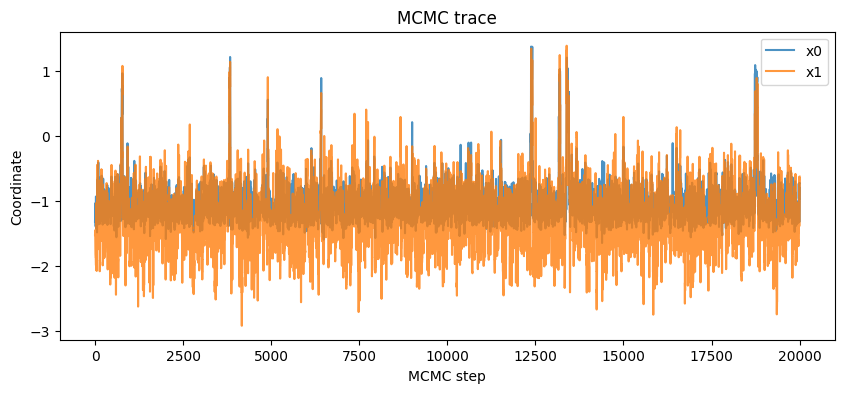

In [5]:

samples, rate = metropolis(
    n_samples=20000,
    kBT=1.0,
    step_size=0.5
)

plt.figure(figsize=(10, 4))

plt.plot(samples[:, 0], label="x0", alpha=0.8)
plt.plot(samples[:, 1], label="x1", alpha=0.8)

plt.xlabel("MCMC step")
plt.ylabel("Coordinate")
plt.title("MCMC trace")
plt.legend()
plt.show()


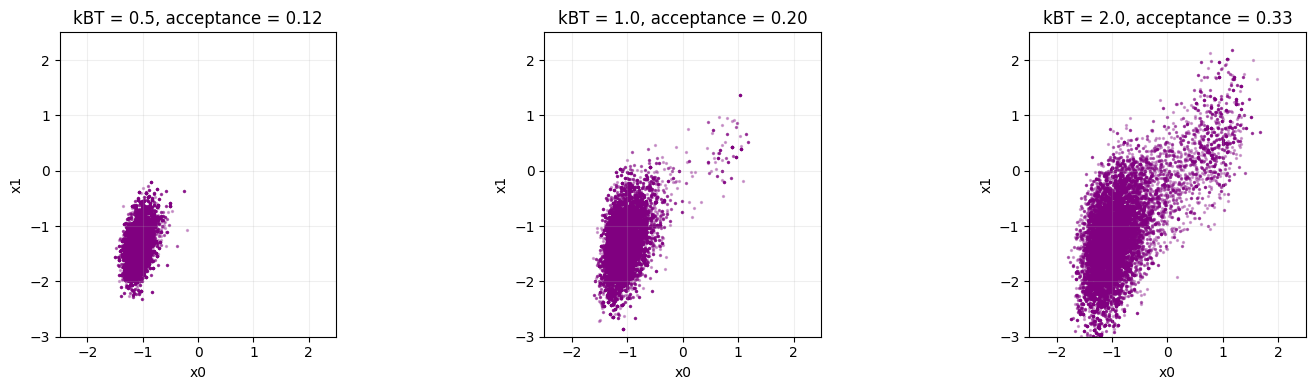

In [6]:

temperatures = [0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, T in zip(axes, temperatures):
    samples, rate = metropolis(
        n_samples=20000,
        kBT=T,
        step_size=0.7,
        burn_in=5000
    )

    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.3, color="purple")
    ax.set_title(f"kBT = {T}, acceptance = {rate:.2f}")
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 2.5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


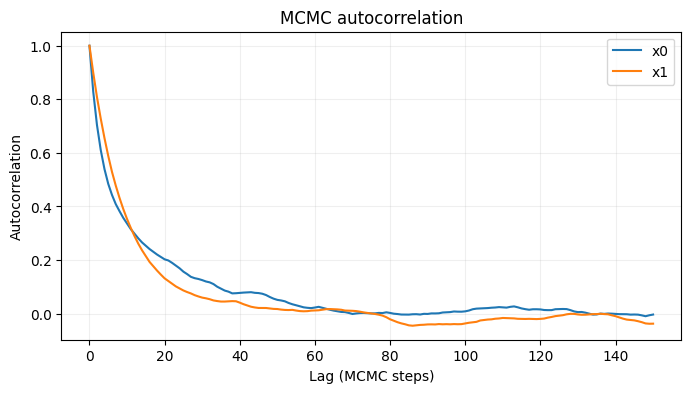

In [7]:

def autocorrelation(x, max_lag=150):
    x = x - np.mean(x)
    variance = np.dot(x, x)

    acf = []

    for lag in range(max_lag + 1):
        correlation = np.dot(x[:len(x)-lag], x[lag:]) / variance
        acf.append(correlation)

    return np.array(acf)


samples, rate = metropolis(
    n_samples=20000,
    kBT=1.0,
    step_size=0.5,
    burn_in=5000
)

acf_x0 = autocorrelation(samples[:, 0])
acf_x1 = autocorrelation(samples[:, 1])

plt.figure(figsize=(8, 4))
plt.plot(acf_x0, label="x0")
plt.plot(acf_x1, label="x1")

plt.xlabel("Lag (MCMC steps)")
plt.ylabel("Autocorrelation")
plt.title("MCMC autocorrelation")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


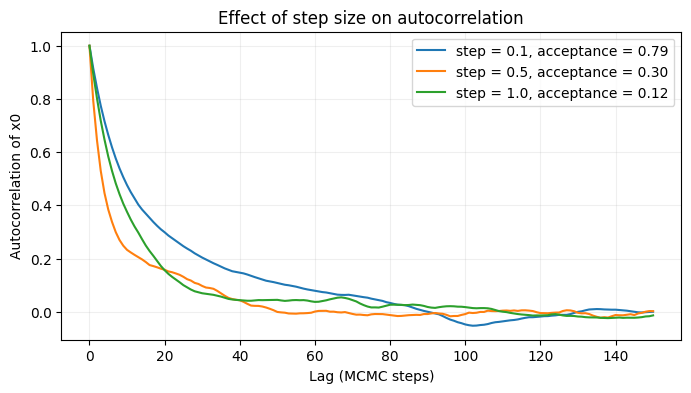

In [8]:

plt.figure(figsize=(8, 4))

for step in [0.1, 0.5, 1.0]:
    samples, rate = metropolis(
        n_samples=20000,
        kBT=1.0,
        step_size=step,
        burn_in=5000
    )

    acf = autocorrelation(samples[:, 0])

    plt.plot(acf, label=f"step = {step}, acceptance = {rate:.2f}")

plt.xlabel("Lag (MCMC steps)")
plt.ylabel("Autocorrelation of x0")
plt.title("Effect of step size on autocorrelation")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


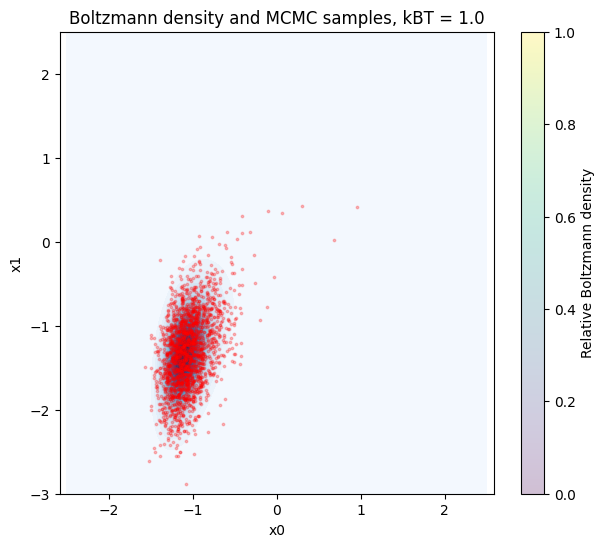

In [9]:

T = 1.0

samples, rate = metropolis(
    n_samples=20000,
    kBT=T,
    step_size=0.5,
    burn_in=5000
)

x0 = np.linspace(-2.5, 2.5, 200)
x1 = np.linspace(-3, 2.5, 200)

X0, X1 = np.meshgrid(x0, x1)

V = eps * (c * (X0**2 - 1)**2 + (X0 - X1)**2 + d * (X0 + X1))

P = np.exp(-(V - V.min()) / T)

plt.figure(figsize=(7, 6))

plt.contourf(X0, X1, P, levels=30, cmap="Blues")
plt.scatter(samples[::10, 0], samples[::10, 1],
            s=3, color="red", alpha=0.25)

plt.xlabel("x0")
plt.ylabel("x1")
plt.title(f"Boltzmann density and MCMC samples, kBT = {T}")
plt.colorbar(label="Relative Boltzmann density")
plt.axis("equal")
plt.show()


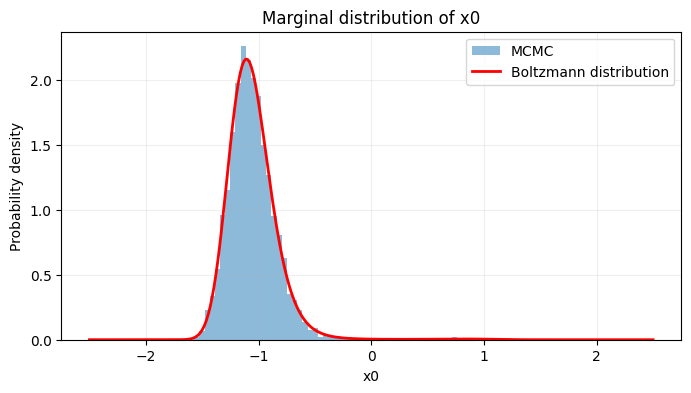

In [10]:

T = 1.0

samples, rate = metropolis(
    n_samples=20000,
    kBT=T,
    step_size=0.5,
    burn_in=5000
)

x0 = np.linspace(-2.5, 2.5, 300)
x1 = np.linspace(-3.5, 3.0, 300)

X0, X1 = np.meshgrid(x0, x1)

V = eps * (
    c * (X0**2 - 1)**2
    + (X0 - X1)**2
    + d * (X0 + X1)
)

P = np.exp(-(V - V.min()) / T)

# Integrate out x1 to obtain p(x0)
p_x0 = np.trapezoid(P, x1, axis=0)

# Normalize the probability density
p_x0 /= np.trapezoid(p_x0, x0)

plt.figure(figsize=(8, 4))

plt.hist(samples[:, 0], bins=60, density=True,
         alpha=0.5, label="MCMC")

plt.plot(x0, p_x0, color="red", linewidth=2,
         label="Boltzmann distribution")

plt.xlabel("x0")
plt.ylabel("Probability density")
plt.title("Marginal distribution of x0")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


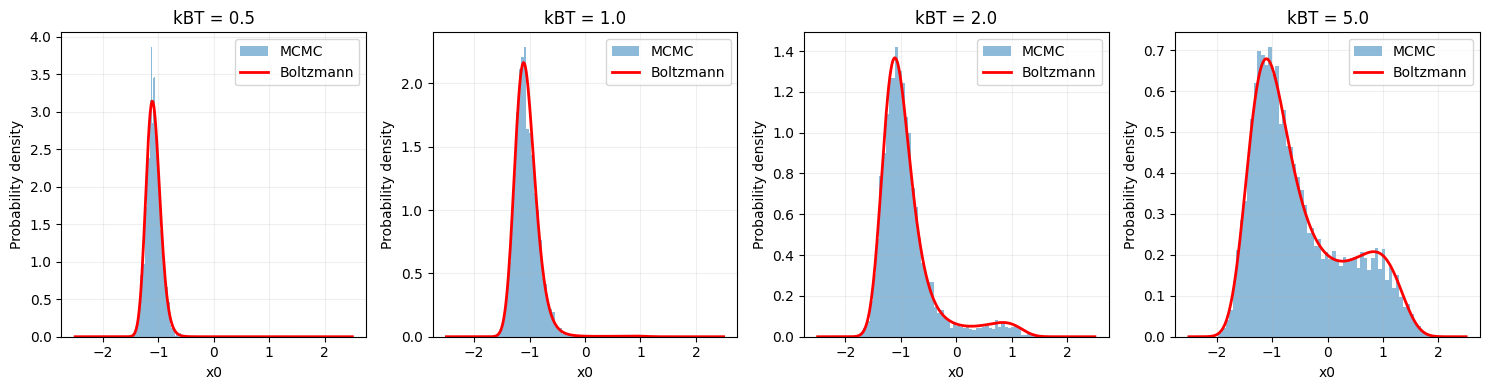

In [11]:

temperatures = [0.5, 1.0, 2.0, 5.0]
x0 = np.linspace(-2.5, 2.5, 300)
x1 = np.linspace(-3.5, 3.0, 300)
X0, X1 = np.meshgrid(x0, x1)
V = eps * (c * (X0**2 - 1)**2 + (X0 - X1)**2 + d * (X0 + X1))

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, T in zip(axes, temperatures):
    samples, rate = metropolis(
        n_samples=20000,
        kBT=T,
        step_size=0.5,
        burn_in=5000
    )

    P = np.exp(-(V - V.min()) / T)
    p_x0 = np.trapezoid(P, x1, axis=0)
    p_x0 /= np.trapezoid(p_x0, x0)

    ax.hist(samples[:, 0], bins=60, density=True,
            alpha=0.5, label="MCMC")

    ax.plot(x0, p_x0, color="red", linewidth=2,
            label="Boltzmann")

    ax.set_title(f"kBT = {T}")
    ax.set_xlabel("x0")
    ax.set_ylabel("Probability density")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [12]:

def effective_sample_size(x, max_lag=1000):
    acf = autocorrelation(x, max_lag=min(max_lag, len(x)-1))

    tau = 1.0

    for lag in range(1, len(acf)):
        if acf[lag] <= 0:
            break
        tau += 2 * acf[lag]

    return len(x) / tau


samples, rate = metropolis(
    n_samples=20000,
    kBT=1.0,
    step_size=0.5,
    burn_in=5000
)

ess_x0 = effective_sample_size(samples[:, 0])
ess_x1 = effective_sample_size(samples[:, 1])

print(f"Total samples: {len(samples)}")
print(f"ESS for x0: {ess_x0:.0f}")
print(f"ESS for x1: {ess_x1:.0f}")


Total samples: 20000
ESS for x0: 1273
ESS for x1: 1114


In [13]:

temperatures = [0.5, 1.0, 2.0]

training_data = {}

for T in temperatures:
    samples, rate = metropolis(
        n_samples=20000,
        kBT=T,
        step_size=0.5,
        burn_in=5000
    )

    training_data[T] = samples

    print(f"kBT = {T}: {samples.shape[0]} samples")


kBT = 0.5: 20000 samples
kBT = 1.0: 20000 samples
kBT = 2.0: 20000 samples


## 4. Stochastic-interpolant neural network

We keep the architecture from the previous notebook: `3 → 256 → 256 → 256 → 2`, with ReLU activations. The network takes position $x\in\mathbb R^2$ and time $t$ and returns a two-component velocity $v_\theta(x,t)$.

We use the **trigonometric** interpolant

$$X_t=\cos\left(\frac{\pi t}{2}\right)X_0+\sin\left(\frac{\pi t}{2}\right)X_1,$$

with independent $X_0\sim\mathcal N(0,I)$ and $X_1\sim p_T$. The endpoints are unchanged: $X_{t=0}=X_0$ and $X_{t=1}=X_1$.

In [14]:

class VelocityNetwork(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, t):
        return self.network(torch.cat([x, t], dim=1))


### 4.1 Velocity-matching objective

The supervised velocity target is the **time derivative of the trigonometric interpolant**:

$$\dot X_t=\frac{\pi}{2}\left[-\sin\left(\frac{\pi t}{2}\right)X_0+\cos\left(\frac{\pi t}{2}\right)X_1\right].$$

We minimize $\mathbb E\|v_\theta(X_t,t)-\dot X_t\|^2$. **Both** `xt` and `target_velocity` must change when switching from linear to trigonometric interpolation.

Minimizing the population mean-squared error gives the conditional mean velocity $v^*(t,x)=\mathbb E[\dot X_t\mid X_t=x]$.

In [15]:

def train_model(samples, n_iterations=10000, batch_size=512, lr=1e-3):
    model = VelocityNetwork(256).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    target_data = torch.tensor(samples, dtype=torch.float32, device=device)
    losses = []

    for i in range(n_iterations):
        indices = torch.randint(0, len(target_data), (batch_size,), device=device)

        x1 = target_data[indices]
        x0 = torch.randn_like(x1)
        t = torch.rand(batch_size, 1, device=device)

        a = 0.5 * torch.pi * t
        xt = torch.cos(a) * x0 + torch.sin(a) * x1
        target_velocity = 0.5 * torch.pi * (-torch.sin(a) * x0 + torch.cos(a) * x1)

        predicted_velocity = model(xt, t)
        loss = ((predicted_velocity - target_velocity)**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    return model, losses


In [16]:

model_1, loss_1 = train_model(
    training_data[1.0],
    n_iterations=10000,
    batch_size=512,
    lr=1e-3
)


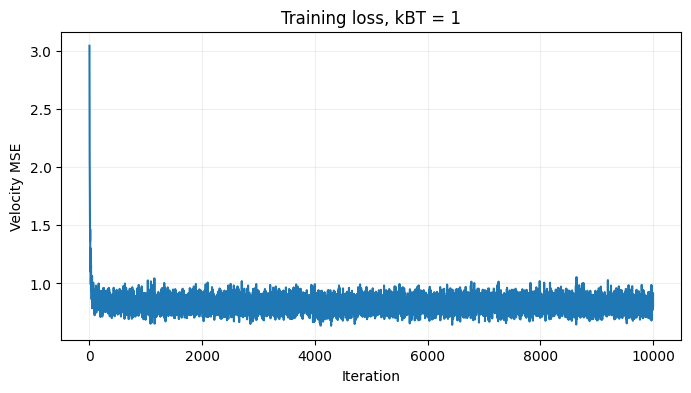

In [17]:

plt.figure(figsize=(8, 4))
plt.plot(loss_1)

plt.xlabel("Iteration")
plt.ylabel("Velocity MSE")
plt.title("Training loss, kBT = 1")
plt.grid(alpha=0.2)

plt.show()


In [18]:

@torch.no_grad()
def generate_samples(model, n_samples=5000, n_steps=100):
    model.eval()

    x = torch.randn(n_samples, 2, device=device)
    dt = 1.0 / n_steps

    for i in range(n_steps):
        t = torch.full((n_samples, 1), i * dt, device=device)

        k1 = model(x, t)
        k2 = model(x + 0.5 * dt * k1, t + 0.5 * dt)
        k3 = model(x + 0.5 * dt * k2, t + 0.5 * dt)
        k4 = model(x + dt * k3, t + dt)

        x = x + (dt / 6) * (k1 + 2*k2 + 2*k3 + k4)

    return x.cpu().numpy()


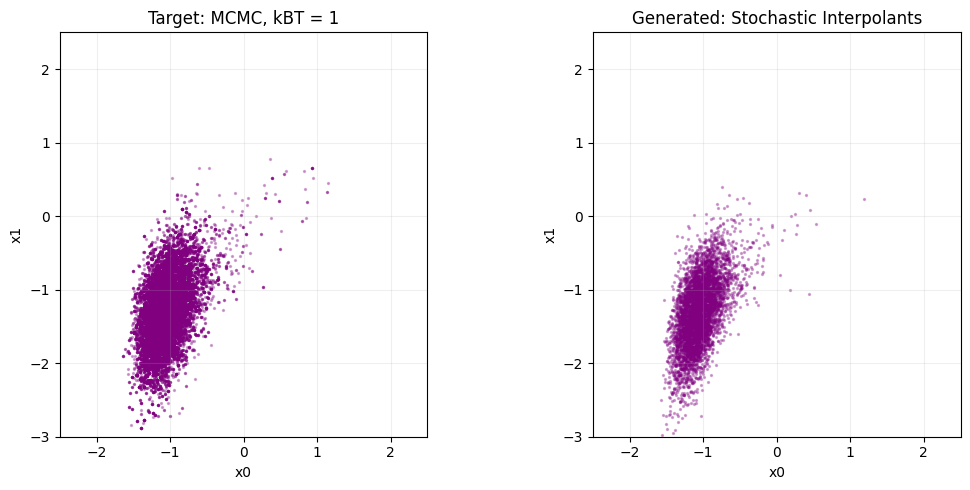

In [19]:

generated = generate_samples(model_1, n_samples=5000, n_steps=100)
target = training_data[1.0]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(target[:, 0], target[:, 1], s=2, alpha=0.3, color="purple")
axes[0].set_title("Target: MCMC, kBT = 1")

axes[1].scatter(generated[:, 0], generated[:, 1], s=2, alpha=0.3, color="purple")
axes[1].set_title("Generated: Stochastic Interpolants")

for ax in axes:
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 2.5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [20]:

models = {1.0: model_1}
losses = {1.0: loss_1}

for T in [0.5, 2.0]:
    models[T], losses[T] = train_model(
        training_data[T],
        n_iterations=10000,
        batch_size=512,
        lr=1e-3
    )


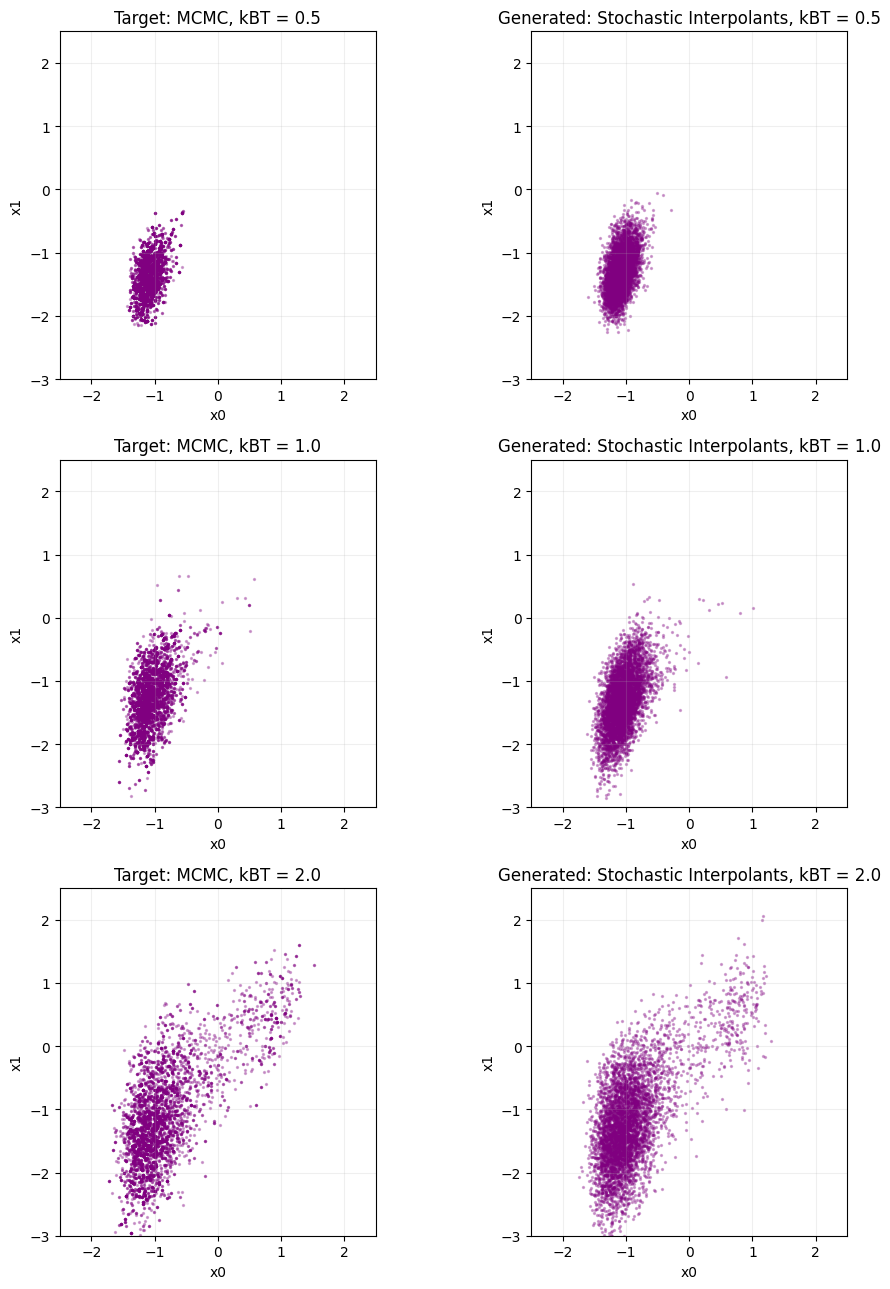

In [21]:

temperatures = [0.5, 1.0, 2.0]
n_samples = 5000

fig, axes = plt.subplots(3, 2, figsize=(10, 13))

for i, T in enumerate(temperatures):
    target = training_data[T][:n_samples]
    generated = generate_samples(models[T], n_samples=n_samples, n_steps=100)

    axes[i, 0].scatter(target[:, 0], target[:, 1], s=2, alpha=0.3, color="purple")
    axes[i, 1].scatter(generated[:, 0], generated[:, 1], s=2, alpha=0.3, color="purple")

    axes[i, 0].set_title(f"Target: MCMC, kBT = {T}")
    axes[i, 1].set_title(f"Generated: Stochastic Interpolants, kBT = {T}")

    for ax in axes[i]:
        ax.set_xlabel("x0")
        ax.set_ylabel("x1")
        ax.set_xlim(-2.5, 2.5)
        ax.set_ylim(-3, 2.5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


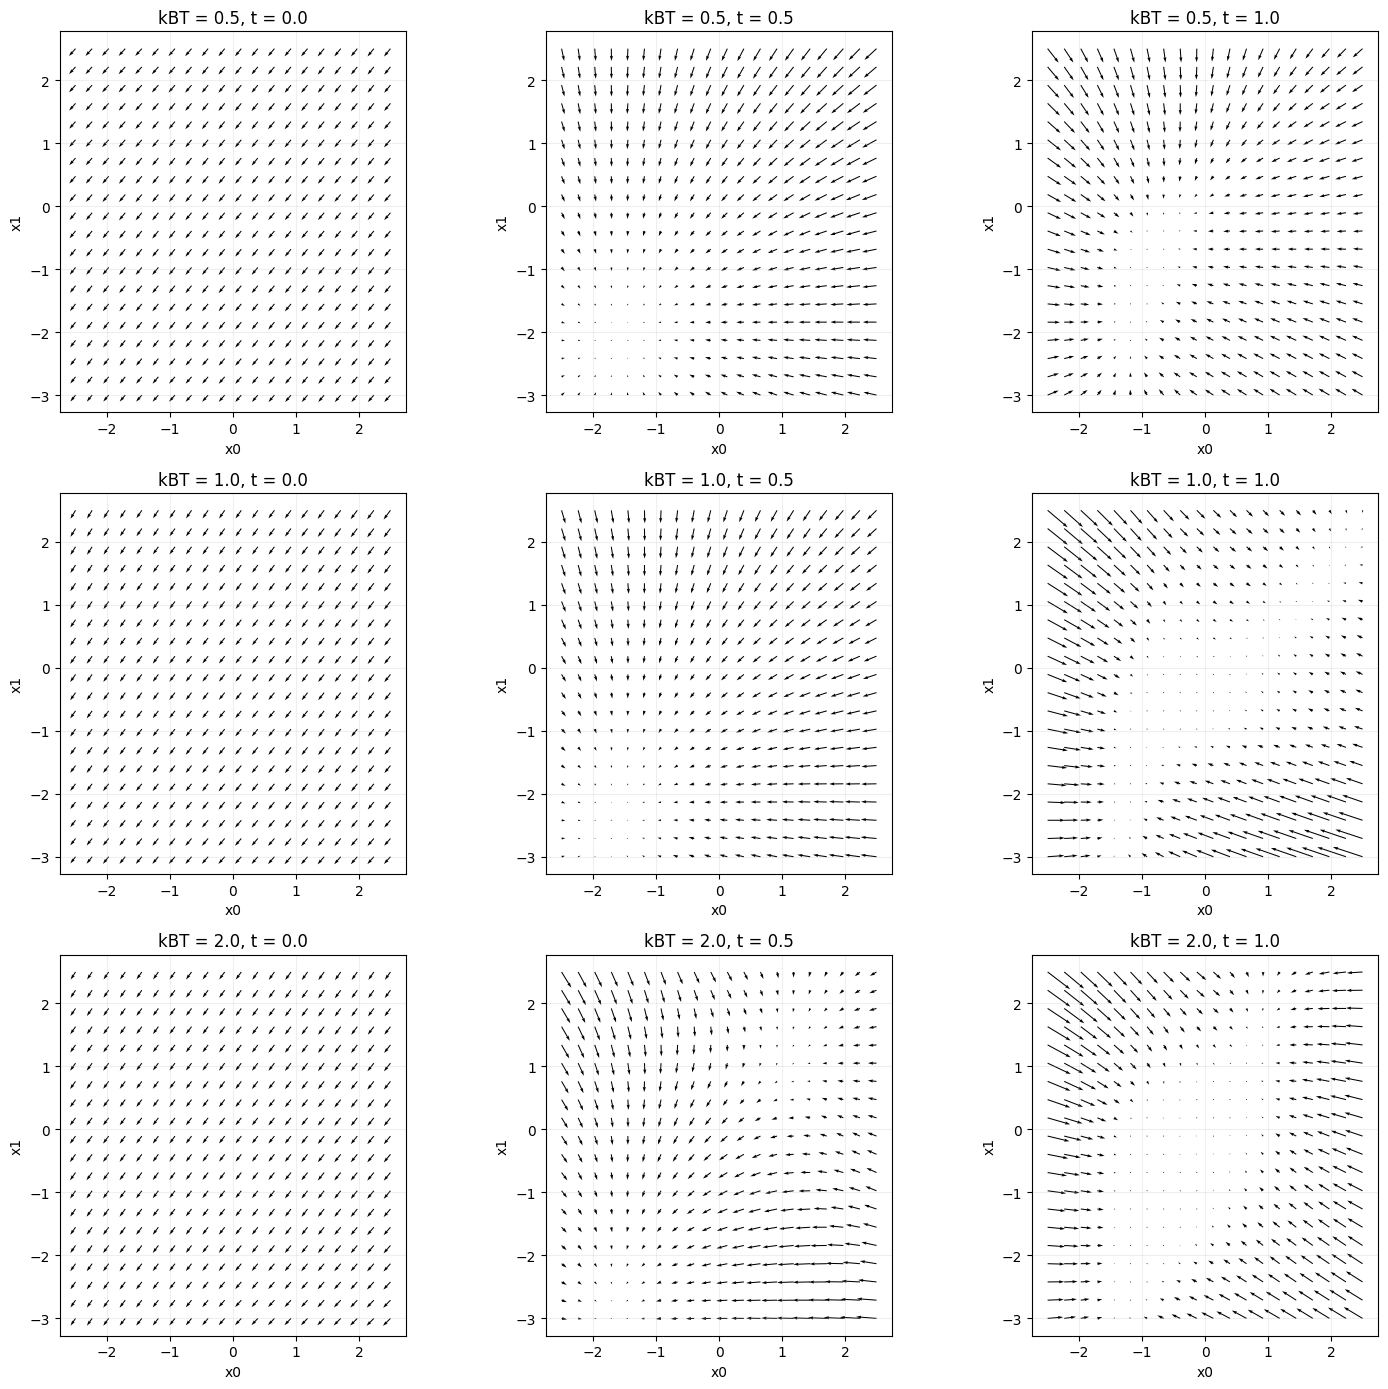

In [22]:

times = [0.0, 0.5, 1.0]
temperatures = [0.5, 1.0, 2.0]

x0 = np.linspace(-2.5, 2.5, 20)
x1 = np.linspace(-3, 2.5, 20)
X0, X1 = np.meshgrid(x0, x1)

grid = torch.tensor(
    np.stack([X0.ravel(), X1.ravel()], axis=1),
    dtype=torch.float32,
    device=device
)

fig, axes = plt.subplots(3, 3, figsize=(15, 14))

for i, T in enumerate(temperatures):
    model = models[T]
    model.eval()

    for j, time in enumerate(times):
        t = torch.full((len(grid), 1), time, device=device)

        with torch.no_grad():
            velocity = model(grid, t).cpu().numpy()

        U = velocity[:, 0].reshape(X0.shape)
        V = velocity[:, 1].reshape(X1.shape)

        ax = axes[i, j]
        ax.quiver(X0, X1, U, V)

        ax.set_title(f"kBT = {T}, t = {time}")
        ax.set_xlabel("x0")
        ax.set_ylabel("x1")
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [23]:

dataset_sizes = [1000, 5000, 20000]

size_models = {}
size_losses = {}

for n in dataset_sizes:
    print(f"Training with {n} samples...")

    size_models[n], size_losses[n] = train_model(
        training_data[1.0][:n],
        n_iterations=10000,
        batch_size=512,
        lr=1e-3
    )


Training with 1000 samples...
Training with 5000 samples...
Training with 20000 samples...


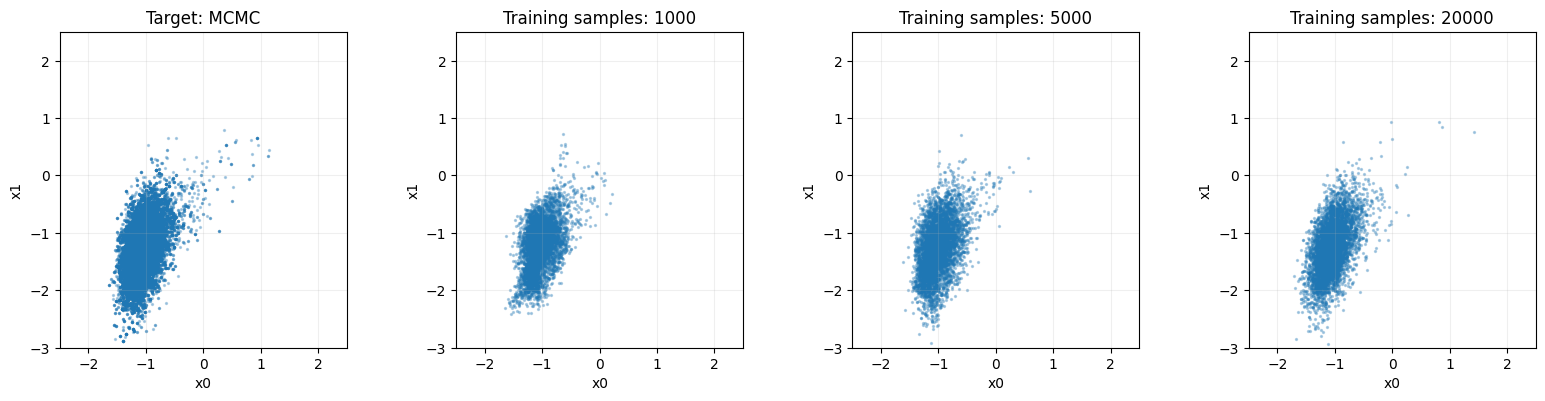

In [24]:

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

target = training_data[1.0]

axes[0].scatter(target[:, 0], target[:, 1], s=2, alpha=0.3)
axes[0].set_title("Target: MCMC")

for i, n in enumerate(dataset_sizes):
    generated = generate_samples(
        size_models[n],
        n_samples=5000,
        n_steps=100
    )

    axes[i+1].scatter(
        generated[:, 0], generated[:, 1],
        s=2, alpha=0.3
    )
    axes[i+1].set_title(f"Training samples: {n}")

for ax in axes:
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 2.5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


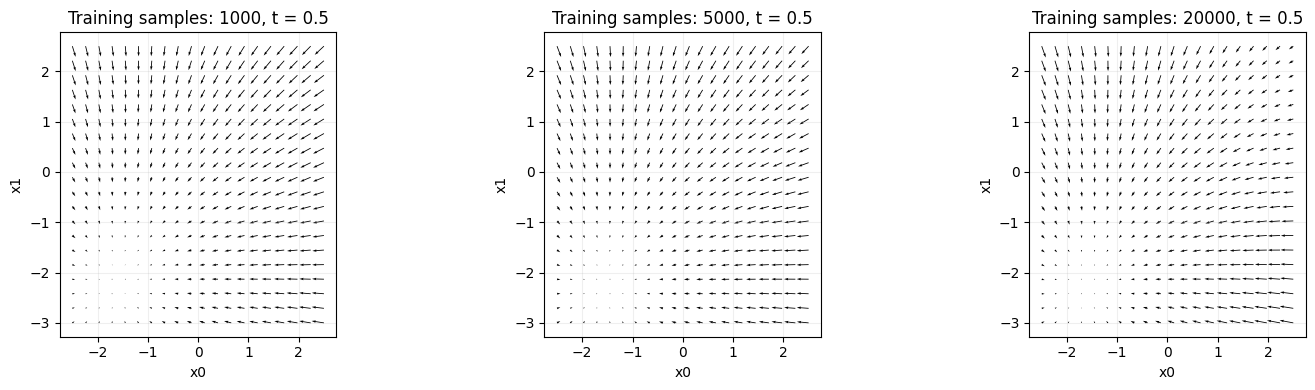

In [25]:

x0 = np.linspace(-2.5, 2.5, 20)
x1 = np.linspace(-3, 2.5, 20)
X0, X1 = np.meshgrid(x0, x1)

grid = torch.tensor(
    np.stack([X0.ravel(), X1.ravel()], axis=1),
    dtype=torch.float32,
    device=device
)

t = torch.full((len(grid), 1), 0.5, device=device)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, n in zip(axes, dataset_sizes):
    model = size_models[n]
    model.eval()

    with torch.no_grad():
        velocity = model(grid, t).cpu().numpy()

    U = velocity[:, 0].reshape(X0.shape)
    V = velocity[:, 1].reshape(X1.shape)

    ax.quiver(X0, X1, U, V)
    ax.set_title(f"Training samples: {n}, t = 0.5")
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()
